In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path('/Users/zhu/Desktop/实习项目/盈远数据')
MERGED = ROOT / 'merged_data'              # 任务 1 生成的合并数据
ATT = ROOT / '测试题'                      # 附件目录(PCF、现金差额、债券条款)
BONDS=['019742','019776','019789']
ETF='511130'
START,END='2026-01-01','2026-02-28'     # 回测区间
LOT=10      # 债券 1 手 = 10 张, 每张面值 100 元

# 计算现金差额

In [ ]:
def load_basket_params(start=START, end=END):
    """
    生成每个交易日的申赎参数表, 每行是一个交易日 D:
      qty_xxx   : D 日一个申赎单位里各债券的数量(张)
      unit      : 最小申赎单位(份)
      est_cash  : D 日盘中可见的预估现金部分 -> 用于算 IOPV 和信号
      real_cash : D 日收盘后公布的实际现金差额 -> 用于结算
      prev_nav  : 上一交易日的每份净值 -> 仅用于核对 IOPV 是否合理
      cash_adj  : real_cash - est_cash, 收盘后每个申赎单位的结算调整额
    """
    pcf=pd.read_csv(ATT/'511130_PCF清单_2024-12-31_2026-03-20.csv',encoding='utf-8-sig', parse_dates=['date'])
    pcf['code']=pcf['stock_code'].str[:6]
    qty=pcf.pivot(index='date',columns='code',values='stock_amount')

    qty = (qty[BONDS] * LOT).add_prefix('qty_')        # 手 -> 张
    # 现金差额
    cash=pd.read_csv(ATT/"511130_现金差额_2024-12-31_2026-03-20.csv",encoding='utf-8-sig',parse_dates=['pre_date'])
    cash=cash.sort_values('pre_date').set_index('pre_date')
    cash.index.name = 'date'
    out=pd.DataFrame({
        'unit': cash['unit_subscribe_redeem'],
        # D 行的预估值是给 D+1 日用的, 所以整体下移一行
        'est_cash':cash['est_cash_component'].shift(1),
        # 该日的实际现金差额
        'real_cash': cash['cash_component'],
        'prev_nav': cash['nav_per_basket'].shift(1) / cash['unit_subscribe_redeem'].shift(1)
    })
    params=qty.join(out, how='inner').loc[start:end]
    assert params.notna().all().all(), '参数表存在缺失值'
    qty_cols = [f'qty_{b}' for b in BONDS]
    params[qty_cols] = params[qty_cols].astype(int)
    params['cash_adj'] = params['real_cash'] - params['est_cash']
    return params

params=load_basket_params()
params

,qty_019742,qty_019776,qty_019789,unit,est_cash,real_cash,prev_nav,cash_adj
date,,,,,,,,
2026-01-05,2000,4000,4000,10000,71935.94,71826.08,104.333446,-109.86
2026-01-06,2000,4000,4000,10000,71772.23,71184.98,104.008920,-587.25
2026-01-07,2000,4000,5000,10000,-26263.96,-26257.45,103.402635,6.51
2026-01-08,2000,4000,5000,10000,-26329.38,-26424.66,102.748327,-95.28
2026-01-09,2000,4000,5000,10000,-26493.50,-26429.66,103.151019,63.84
2026-01-12,2000,4000,5000,10000,-26598.88,-26309.80,103.239932,289.08
2026-01-13,2000,4000,5000,10000,-26379.33,-26234.50,103.692160,144.83
2026-01-14,2000,4000,5000,10000,-26322.94,-26090.93,103.845103,232.01
2026-01-15,2000,4000,5000,10000,-26167.98,-26179.90,103.659873,-11.92


# 计算应计利息

In [6]:
# 债券条款, 取自附件《基本条款》: 票面利率(%), 起息日; 三只都是每年付息 2 次, 计息基准 A/365F
BOND_TERMS = {
    '019742': {'coupon': 2.57, 'value_date': '2024-05-20'},
    '019776': {'coupon': 1.88, 'value_date': '2025-04-25'},
    '019789': {'coupon': 2.15, 'value_date': '2025-08-25'},
}
FREQ_MONTHS = 6   # 半年付息


def accrued_interest(code, date, include_trade_day=True):
    """每 100 元面值的应计利息 = 100 × 票面利率 × 已计息天数 / 365"""
    term = BOND_TERMS[code]
    date=pd.Timestamp(date).normalize()
    # 从起息日开始每次加 6 个月, 找到 date 之前(含当天)最近的一个付息日
    last=pd.Timestamp(term['value_date'])
    while last+pd.DateOffset(months=FREQ_MONTHS)<=date:
        last = last + pd.DateOffset(months=FREQ_MONTHS)
    # 交易所债券计息天数"算头又算尾": 从上一付息日到成交日, 两头都算
    days = (date - last).days + (1 if include_trade_day else 0)
    return 100 * term['coupon'] / 100 * days / 365

# 计算每个交易日，每只债券的应计利息
ai=pd.DataFrame({f'ai_{b}': [accrued_interest(b, d) for d in params.index] for b in BONDS},index=params.index)
ai.loc[['2026-01-05', "2026-01-06",'2026-02-24', '2026-02-25', '2026-02-27']]



,ai_019742,ai_019776,ai_019789
date,,,
2026-01-05,0.330932,0.376000,0.789315
2026-01-06,0.337973,0.381151,0.795205
2026-02-24,0.682986,0.633534,1.083836
2026-02-25,0.690027,0.638685,0.005890
2026-02-27,0.704110,0.648986,0.017671


# 计算IOPV

In [7]:
def load_merged(code):
    """读取任务 1 的合并文件, 只取需要的列"""
    f = MERGED / f"{code}_{START.replace('-', '')}_{END.replace('-', '')}_merged.csv"
    df=pd.read_csv(f,parse_dates=['trade_time'],usecols=['trade_time','last', 'bid_price1', 'ask_price1'])
    return df.sort_values('trade_time')

def build_panel(params,ai):
    """以 ETF 的时间轴为基准, 把三只债券对齐上来, 并计算 IOPV"""
    panel=load_merged(ETF).rename(columns={'last':'etf_last','bid_price1':'etf_bid','ask_price1':'etf_ask'})
    panel['date']=panel['trade_time'].dt.normalize()
    for b in BONDS:
        bd=load_merged(b).rename(columns={'last': f'last_{b}', 'bid_price1': f'bid_{b}', 'ask_price1': f'ask_{b}'})
        bd['date']=bd['trade_time'].dt.normalize()
        bd[f'time_{b}']=bd['trade_time']    # # 记下债券报价自己的时间, 用来算"有多旧"
        # 对每个 ETF 时点, 取该时点之前(含)最近的一条债券快照; by='date' 保证不跨日
        panel = pd.merge_asof(panel, bd, on='trade_time', by='date', direction='backward')

    n0 = len(panel)
    panel=panel.dropna(subset=[f'last_{b}' for b in BONDS])
    print(f'对齐后 {n0:,} 行, 去掉债券当日尚未成交的行后 {len(panel):,} 行')
    # 接上当日的篮子参数和应计利息
    panel=panel.join(params,on='date').join(ai,on='date')
    # IOPV(每份) = (Σ 数量 × (净价 + 应计利息) + 预估现金) / 申赎单位
    # iopv_last: 按最新成交价
    # iopv_ask : 按卖一价 = 现在买齐一篮子的成本
    # iopv_bid : 按买一价 = 现在卖掉一篮子能收回的钱
    for tag in ('last','bid','ask'):
        basket=sum(panel[f'qty_{b}']*(panel[f'{tag}_{b}']+ panel[f'ai_{b}']) for b in BONDS)
        panel[f'iopv_{tag}']=(basket+panel['est_cash'])/panel['unit']

    lag=[(panel['trade_time'] - panel[f'time_{b}']).dt.total_seconds() for b in BONDS]
    panel['stale_sec'] = pd.concat(lag, axis=1).max(axis=1)
    panel['premium'] = panel['etf_last'] - panel['iopv_last']   # 正 = ETF 溢价
    return panel.drop(columns=[f'time_{b}' for b in BONDS]).reset_index(drop=True)

panel = build_panel(params, ai)
panel[['trade_time', 'etf_last', 'iopv_last', 'iopv_bid', 'iopv_ask', 'premium', 'stale_sec']].head()

对齐后 162,921 行, 去掉债券当日尚未成交的行后 161,700 行


,trade_time,etf_last,iopv_last,iopv_bid,iopv_ask,premium,stale_sec
0,2026-01-05 09:30:47,104.103,104.158706,104.077306,104.278306,-0.055706,2.0
1,2026-01-05 09:30:50,104.102,104.158306,104.077106,104.361106,-0.056306,2.0
2,2026-01-05 09:30:53,104.079,104.158306,104.077906,104.361106,-0.079306,2.0
3,2026-01-05 09:30:56,104.080,104.158306,104.081306,104.361106,-0.078306,2.0
4,2026-01-05 09:30:59,104.080,104.158306,104.081906,104.361106,-0.078306,2.0


# 策略实现

In [12]:
import backtrader as bt
ETF_FEE=0.5e-4  # # ETF 单边费率 万 0.5
BOND_FEE=0.05e-4   # 债券费率 万 0.05

class EtfData(bt.feeds.PandasData):
    """ETF 数据源, 额外带上 IOPV 和债券报价滞后秒数两列"""
    lines=('iopv','stale_sec','etf_bid', 'etf_ask', 'iopv_bid', 'iopv_ask')
    # -1表示自动按字段名查找对应列
    params = tuple((name, -1) for name in lines)
    
def make_feeds(panel):
    """把面板拆成 4 个数据源: ETF + 3 只债券(债券用全价)"""
    idx=pd.DatetimeIndex(panel['trade_time'])

    def ohlc(price):
        # 快照数据只有一个价格, 开高低收都用它
        return pd.DataFrame({'open': price, 'high': price, 'low': price, 'close': price,
                             'volume': 0.0, 'openinterest': 0.0}, index=idx)
    
    etf=ohlc(panel['etf_last'].values)
    etf['iopv'] = panel['iopv_last'].values
    for col in ('stale_sec', 'etf_bid', 'etf_ask', 'iopv_bid', 'iopv_ask'):
        etf[col] = panel[col].values
    feeds = {'ETF': EtfData(dataname=etf)}
    for b in BONDS:
        full_price = (panel[f'last_{b}'] + panel[f'ai_{b}']).values   # 全价 = 净价 + 应计利息
        feeds[b] = bt.feeds.PandasData(dataname=ohlc(full_price))
    return feeds

class CreationRedemptionArb(bt.Strategy):
    params = dict(
        basket=None,             # 每日篮子参数表(params)
        max_capital=10_000_000,  # 仓位上限: 单笔套利最多占用的资金
        max_units=5,             # 单次交易数量上限(申赎单位数, 1 单位 = 10000 份)
        # ---- 每日约束 ----
        max_create_day=None,     # 当日累计申购上限(单位数), None = 不限
        max_redeem_day=1000,     # 当日累计赎回上限(单位数), 取自 2026-03-17 申赎清单
        max_trades_day=None,     # 每日最大交易次数, None = 不限
        # 成交口径
        slippage=False,          # False: 按最新成交价(题目口径); True: 按盘口价(买按卖一, 卖按买一)
        min_profit=0.0,          # 扣除成本后的最小利润门槛(元/份)
        max_stale=None,          # 债券报价滞后超过多少秒就不交易, None = 不过滤
        cooldown=0,              # 两笔交易之间的最小间隔(秒), 0 = 不限制
    )

    def __init__(self):
        self.etf = self.getdatabyname('ETF')
        self.bonds = {b: self.getdatabyname(b) for b in BONDS}
        self.pending = None          # 已下单、等待换仓的套利: (方向, 单位数, 日期)
        self.last_trade_time=None
        self.day_net_units=0    # # 当日净申购单位数(申购为正, 赎回为负)
        self.day_units = {1: 0, -1: 0}    # 当日累计申购 / 赎回单位数, 用于每日上限
        self.day_trades = 0               # 当日交易次数
        self.trades=[]      # 交易记录
        self.equity=[]      # 资金曲线

    def _adjust_cash(self,amount):
        """直接调整账户现金: 用于申赎的现金差额收付(backtrader没有对应的原生操作)"""
        self.broker.cash += amount

    def _convert(self):
        """换仓: 模拟申购/赎回, 把 ETF 和债券持仓清零, 并按预估现金收付"""
        side, n, day,slip = self.pending
        row = self.p.basket.loc[day]
        for d in [self.etf] + list(self.bonds.values()):
            pos = self.broker.getposition(d)
            pos.update(-pos.size, d.close[0])
        # 申购(side=1)要付现金差额, 赎回(side=-1)收到现金差额
        self._adjust_cash(-side * n * row['est_cash'])
        self._adjust_cash(-slip)    # 盘口价与最新成交价之差
        self.day_net_units += side * n
        self.pending = None

    def _settle_day(self,date):
        """收盘结算: 按实际现金差额多退少补"""
        if self.day_net_units != 0:
            adj = self.p.basket.loc[pd.Timestamp(date), 'cash_adj']   # 实际 - 预估
            self._adjust_cash(-adj * self.day_net_units)
        self.day_net_units = 0
        self.day_units = {1: 0, -1: 0}
        self.day_trades = 0


    def next(self):
        now = self.etf.datetime.datetime(0)
        today = pd.Timestamp(now.date())
        # 1) 上一根下的单此时已成交, 先完成换仓
        if self.pending is not None:
            self._convert()
        
        # 2) 当天最后一根: 做收盘结算, 且不再开新交易
        is_last_bar = len(self.etf) >= self.etf.buflen()
        day_end = is_last_bar or pd.Timestamp(self.etf.datetime.datetime(1).date()) != today
        if day_end:
            self._settle_day(today)
        self.equity.append((now, self.broker.getcash()))   # 换仓后无持仓, 现金即总资产
        if day_end:
            return
        # 3) 计算信号
        row = self.p.basket.loc[today]
        unit = row['unit']
        etf_px, iopv = self.etf.close[0], self.etf.iopv[0]
        basket_val = sum(row[f'qty_{b}'] * self.bonds[b].close[0] for b in BONDS)
        cost = etf_px * ETF_FEE + basket_val / unit * BOND_FEE     # 每份的交易成本
        premium = etf_px - iopv

        if self.p.slippage:
            # 申购套利: ETF 按买一卖出, 债券按卖一买入
            edge_create = self.etf.etf_bid[0] - self.etf.iopv_ask[0]
            # 赎回套利: ETF 按卖一买入, 债券按买一卖出
            edge_redeem = self.etf.iopv_bid[0] - self.etf.etf_ask[0]
        else:
            edge_create, edge_redeem = premium, -premium

        if edge_create - cost > self.p.min_profit:
            side, edge = 1, edge_create       # ETF 溢价: 买债券 -> 申购 -> 卖 ETF
        elif edge_redeem - cost > self.p.min_profit:
            side, edge = -1, edge_redeem      # ETF 折价: 买 ETF -> 赎回 -> 卖债券
        else:
            return

        # 4) 过滤条件
        if self.p.max_trades_day is not None and self.day_trades >= self.p.max_trades_day:
            return
        if self.p.max_stale is not None and self.etf.stale_sec[0] > self.p.max_stale:
            return
        if (self.last_trade_time is not None
                and (now - self.last_trade_time).total_seconds() < self.p.cooldown):
            return

        # 5) 确定数量: 单次上限、资金上限、当日申赎上限三者取最小
        need = max(basket_val, unit * etf_px) * (1 + ETF_FEE)      # 做 1 个单位需要的资金
        budget = min(self.p.max_capital, self.broker.getcash())
        n = int(min(self.p.max_units, budget // need))
        day_cap = self.p.max_create_day if side == 1 else self.p.max_redeem_day
        if day_cap is not None:
            n = min(n, day_cap - self.day_units[side])
        if n < 1:
            return

        # 6) 下单(订单按最新成交价成交, 滑点在换仓时另行扣除)
        if side == 1:
            self.sell(data=self.etf, size=unit * n)
        else:
            self.buy(data=self.etf, size=unit * n)
        for b in BONDS:
            size = row[f'qty_{b}'] * n
            if side == 1:
                self.buy(data=self.bonds[b], size=size)
            else:
                self.sell(data=self.bonds[b], size=size)

        # 滑点金额 = (按最新成交价的空间 - 按盘口价的空间) × 份数; 不开滑点时为 0
        slip = (side * premium - edge) * unit * n
        self.pending = (side, n, today, slip)
        self.last_trade_time = now
        self.day_units[side] += n
        self.day_trades += 1
        self.trades.append({
            'time': now, 'side': '溢价-申购' if side == 1 else '折价-赎回', 'units': n,
            'etf': etf_px, 'iopv': iopv, 'premium': premium, 'edge': edge,
            'cost': cost, 'slippage': slip,
            'exp_pnl': (edge - cost) * unit * n})   # 按预估现金算的预期利润


        def notify_order(self, order):
            # 任何一条腿没成交都直接报错, 避免出现只成交一半的套利
            if order.status in (order.Margin, order.Rejected, order.Canceled):
                raise RuntimeError(f'订单未成交: {order.data._name} {order.getstatusname()}')

        

def run_backtest(panel, params, **kw):
    cerebro = bt.Cerebro(stdstats=False)
    for name, feed in make_feeds(panel).items():
        cerebro.adddata(feed, name=name)
    cerebro.broker.setcash(kw.get('max_capital', 10_000_000))
    cerebro.broker.set_coc(True)      # 按信号所在快照的价格成交
    cerebro.broker.setcommission(commission=ETF_FEE, name='ETF')
    for b in BONDS:
        cerebro.broker.setcommission(commission=BOND_FEE, name=b)
    cerebro.addstrategy(CreationRedemptionArb, basket=params, **kw)
    strat = cerebro.run()[0]
    equity = pd.Series(dict(strat.equity)).sort_index()
    trades = pd.DataFrame(strat.trades)
    return equity, trades


def metrics(equity, trades, capital):
    daily = equity.groupby(equity.index.normalize()).last()    # 每日收盘资金
    ret = daily.pct_change()
    ret.iloc[0] = daily.iloc[0] / capital - 1
    n = len(daily)
    total = daily.iloc[-1] / capital - 1
    return pd.Series({
        '初始资金': capital,
        '期末资金': daily.iloc[-1],
        '绝对收益(元)': daily.iloc[-1] - capital,
        '绝对收益率': total,
        '年化收益率': (1 + total) ** (252 / n) - 1,
        '夏普比率': ret.mean() / ret.std() * np.sqrt(252),
        '最大回撤': (equity / equity.cummax() - 1).min(),
        '交易次数': len(trades),
        '预期利润合计': trades['exp_pnl'].sum(),
        '滑点合计': trades['slippage'].sum(),
        '交易日数': n})


# ---- 可配置参数 ----
MAX_CAPITAL = 10_000_000   # 仓位上限(策略资金上限)
MAX_UNITS = 5              # 单次交易数量上限(申赎单位)
common = dict(max_capital=MAX_CAPITAL, max_units=MAX_UNITS)

# 版本 A: 不考虑滑点(题目口径)
eq_a, tr_a = run_backtest(panel, params, slippage=False, **common)
# 版本 B: 考虑滑点(按盘口价成交)
eq_b, tr_b = run_backtest(panel, params, slippage=True, **common)

summary = pd.DataFrame({
    '不考虑滑点': metrics(eq_a, tr_a, MAX_CAPITAL),
    '考虑滑点': metrics(eq_b, tr_b, MAX_CAPITAL)})
summary.round(4)

,不考虑滑点,考虑滑点
初始资金,1.000000e+07,1.000000e+07
期末资金,3.433778e+07,9.553606e+06
绝对收益(元),2.433778e+07,-4.463940e+05
绝对收益率,2.433800e+00,-4.460000e-02
年化收益率,9.353436e+03,-2.871000e-01
夏普比率,5.798500e+00,6.359000e-01
最大回撤,-2.879000e-01,-5.904000e-01
交易次数,8.814200e+04,4.063300e+04
预期利润合计,6.223908e+07,2.391474e+07
滑点合计,0.000000e+00,1.605678e+07


# 绘图

max_units=           1 不考虑滑点: 收益      6,588,036 元, 交易 102,078 笔
max_units=           2 不考虑滑点: 收益     11,424,846 元, 交易 95,157 笔
max_units=           5 不考虑滑点: 收益     24,337,780 元, 交易 88,142 笔
max_units=          10 不考虑滑点: 收益     45,223,652 元, 交易 85,345 笔
max_units=           1 考虑滑点: 收益        219,689 元, 交易 44,241 笔
max_units=           2 考虑滑点: 收益        134,095 元, 交易 42,219 笔
max_units=           5 考虑滑点: 收益       -446,394 元, 交易 40,633 笔
max_units=          10 考虑滑点: 收益     -2,264,920 元, 交易 39,453 笔


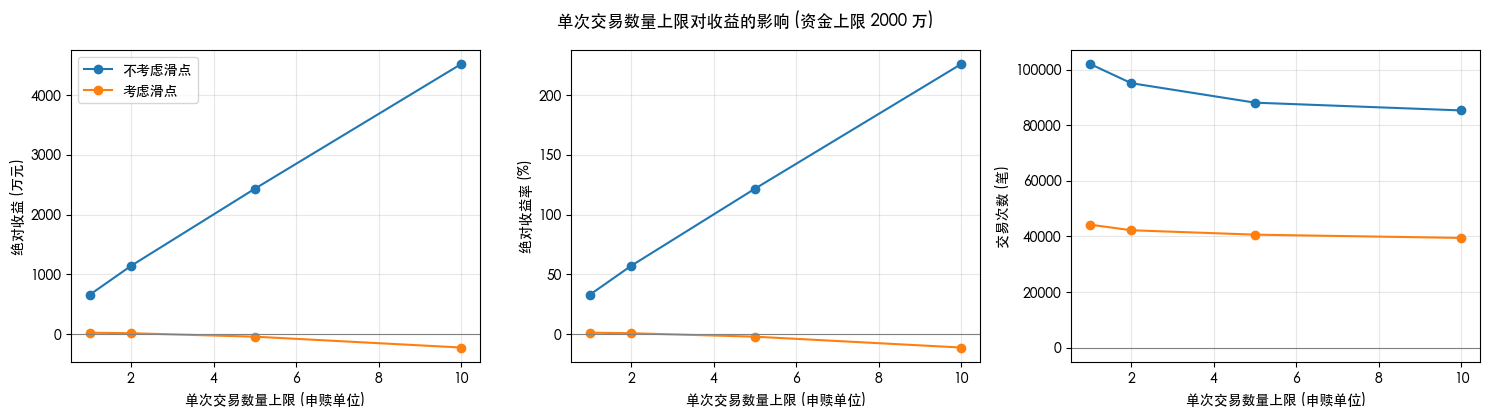

max_capital=   1,500,000 不考虑滑点: 收益      6,588,036 元, 交易 102,078 笔
max_capital=   3,000,000 不考虑滑点: 收益     11,424,846 元, 交易 95,157 笔
max_capital=   5,000,000 不考虑滑点: 收益     20,064,474 元, 交易 89,481 笔
max_capital=  10,000,000 不考虑滑点: 收益     41,068,994 元, 交易 85,693 笔
max_capital=   1,500,000 考虑滑点: 收益        219,689 元, 交易 44,241 笔
max_capital=   3,000,000 考虑滑点: 收益        134,095 元, 交易 42,219 笔
max_capital=   5,000,000 考虑滑点: 收益       -201,686 元, 交易 40,969 笔
max_capital=  10,000,000 考虑滑点: 收益     -1,825,005 元, 交易 39,633 笔


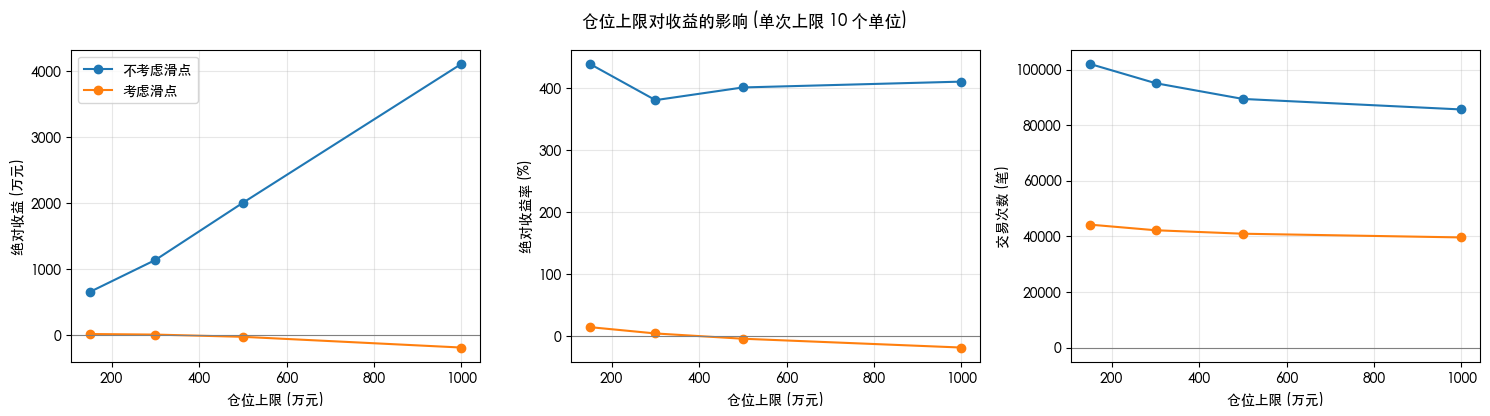

,口径,资金上限(万元),绝对收益(元),绝对收益率,夏普比率,最大回撤,交易次数
0,不考虑滑点,150.0,6.588036e+06,4.392024,6.827442,-0.257101,102078.0
1,不考虑滑点,300.0,1.142485e+07,3.808282,6.257131,-0.279282,95157.0
2,不考虑滑点,500.0,2.006447e+07,4.012895,5.655022,-0.307453,89481.0
3,不考虑滑点,1000.0,4.106899e+07,4.106899,5.319700,-0.328307,85693.0
4,考虑滑点,150.0,2.196885e+05,0.146459,1.492630,-0.615566,44241.0
5,考虑滑点,300.0,1.340949e+05,0.044698,1.164272,-0.637313,42219.0
6,考虑滑点,500.0,-2.016863e+05,-0.040337,1.038274,-0.696555,40969.0
7,考虑滑点,1000.0,-1.825005e+06,-0.182501,0.782460,-0.751555,39633.0


In [13]:
import matplotlib.pyplot as plt
# 中文字体(Mac 上依次尝试这几个)
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti TC', 'Arial Unicode MS', 'SimHei']
plt.rcParams['axes.unicode_minus'] = False

def sweep(panel, params, name, values, fixed):
    """
    参数敏感性扫描: 让参数 name 依次取 values 里的值, 其余参数固定为 fixed,
    每个取值分别跑"不考虑滑点"和"考虑滑点"两版, 返回汇总表
    """
    rows = []
    for slippage in (False, True):
        for v in values:
            kw = dict(fixed, slippage=slippage)
            kw[name] = v
            eq, tr = run_backtest(panel, params, **kw)
            m = metrics(eq, tr, kw['max_capital'])
            m[name] = v
            m['口径'] = '考虑滑点' if slippage else '不考虑滑点'
            rows.append(m)
            print(f"{name}={v:>12,} {m['口径']}: "
                  f"收益 {m['绝对收益(元)']:>14,.0f} 元, 交易 {m['交易次数']:,.0f} 笔")
    return pd.DataFrame(rows)

def plot_sweep(res, xcol, xlabel, title, fname):
    """画三联图: 绝对收益 / 绝对收益率 / 交易次数 随参数的变化, 并保存为 PNG"""
    fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
    panels = [('绝对收益(元)', '绝对收益 (万元)', 1e4),
              ('绝对收益率', '绝对收益率 (%)', 0.01),
              ('交易次数', '交易次数 (笔)', 1)]
    for ax, (col, ylabel, scale) in zip(axes, panels):
        for label, g in res.groupby('口径'):
            ax.plot(g[xcol], g[col] / scale, marker='o', label=label)
        ax.axhline(0, color='grey', lw=0.8)      # 盈亏平衡线
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.suptitle(title)
    fig.tight_layout()
    plt.show()

# 资金固定为 2000 万(足够大, 不构成约束), 只改变单次交易数量上限
res_units = sweep(panel, params, 'max_units', [1, 2, 5, 10],
                  fixed=dict(max_capital=20_000_000))

plot_sweep(res_units, 'max_units', '单次交易数量上限 (申赎单位)',
           '单次交易数量上限对收益的影响 (资金上限 2000 万)', 'sens_max_units.png')

res_units[['口径', 'max_units', '绝对收益(元)', '绝对收益率', '夏普比率', '最大回撤', '交易次数']]


# 单次上限固定为 10 个单位(足够大), 让资金成为约束
res_cap = sweep(panel, params, 'max_capital',
                [1_500_000, 3_000_000, 5_000_000, 10_000_000],
                fixed=dict(max_units=10))
res_cap['资金上限(万元)'] = res_cap['max_capital'] / 1e4

plot_sweep(res_cap, '资金上限(万元)', '仓位上限 (万元)',
           '仓位上限对收益的影响 (单次上限 10 个单位)', 'sens_max_capital.png')

res_cap[['口径', '资金上限(万元)', '绝对收益(元)', '绝对收益率', '夏普比率', '最大回撤', '交易次数']]
